# 感知机

## 说明

感知机是二分类线性模型，几何意义是用一个超平面对空间中样本点进行划分。对于线性可分数据，感知机学习算法能在有限次更新后收敛。对于线性不可分数据，标准感知机可能无法收敛。

 **模型**：$f(x)=sign(w^Tx+b)$

**损失函数**：用误分类点到超平面的总距离来衡量。

单个点到超平面的距离：$d=\dfrac 1{\lVert w\rVert}\lvert w^Tx_0+b\rvert$。

为了方便计算，感知机的损失通常定义为$\lvert w^Tx+b\rvert$。

若$w^Tx_i+b>0$，表明模型将该样本划分为正类；此时若$y_i=-1<0$，则该样本被误分类，此时有$-y_i(w^Tx_i+b)>0$。

因此，误分类点距离可表示为$-\dfrac 1{\lVert w\rVert}y_i(w^Tx_i+b)$

总距离$-\dfrac{1}{\lVert w\rVert}\sum\limits_{x\in M}y_i(w^Tx_i+b)$，其中$M$是误分类点的集合。

损失函数：$L(w,b)=-\sum\limits_{x\in M}y_i(w^Tx_i+b)$

针对三个样本，有梯度：$\dfrac{\partial L}{\partial w} = -x_iy_i,\dfrac{\partial L}{\partial b} = -y_i$

从而$w\gets w+\eta y_ix_i, b\gets b+\eta y_i$

## 过程

每遍历到一个满足$y_i(w^Tx_i+b)\leq 0$的误分类点，就立即用梯度下降对模型参数$w,b$进行更新。

不断重复遍历训练集，直到某一轮没有误分类点（或者超出设置的最大迭代轮数，防止因数据不是线性可分而无限循环）

## 实践

题目：

一家工厂用两个指标判断零件是否合格：
- $x_1$：强度指标
- $x_2$：耐磨指标
- $y=1$：合格
- $y=-1$：不合格
训练数据如下：

In [1]:
import numpy as np

# 训练集
X_train = np.array([
    [1, 2],
    [2, 2],
    [3, 1],
    [1, 4],
    [4, 1],
    [2, 3],

    [3, 4],
    [4, 3],
    [2, 5],
    [5, 2],
    [4, 4],
    [5, 3]
], dtype=float)

y_train = np.array([
    -1, -1, -1, -1, -1, -1,
     1,  1,  1,  1,  1,  1
])
X_train.shape, y_train.shape

((12, 2), (12,))

设置模型、初始化参数

In [2]:
w = np.zeros(2)
b = 0
alpha = 0.1
max_epochs = 1000
w.shape

(2,)

开始训练

In [3]:
for epoch in range(max_epochs):
    mistakes = 0
    for i in range(len(X_train)):
        margin = y_train[i] * (X_train[i] @ w + b)
        if margin <= 0: # 误分类点
            mistakes += 1
            w += alpha * X_train[i] * y_train[i]
            b += alpha * y_train[i]
    if mistakes == 0:
        print(f"分类完成，epochs={epoch + 1}")
        break
else:
    print("达到最大迭代次数，模型可能没有收敛")

分类完成，epochs=29


测试集，预测结果应为 `[-1, -1, 1, 1]`

In [4]:
X_test = np.array([
    [1, 3],
    [3, 2],
    [3, 5],
    [5, 4]
], dtype=float)

y_expected = [-1, -1, 1, 1]

y_test = [1 if x @ w + b > 0 else -1 for x in X_test]
print(
    "预测全部正确" 
    if all(a == b for a, b in zip(y_test, y_expected))
    else "预测错误"
    )
y_test, w, b

预测全部正确


([-1, -1, 1, 1], array([0.4, 0.3]), np.float64(-2.2000000000000006))

## 画图

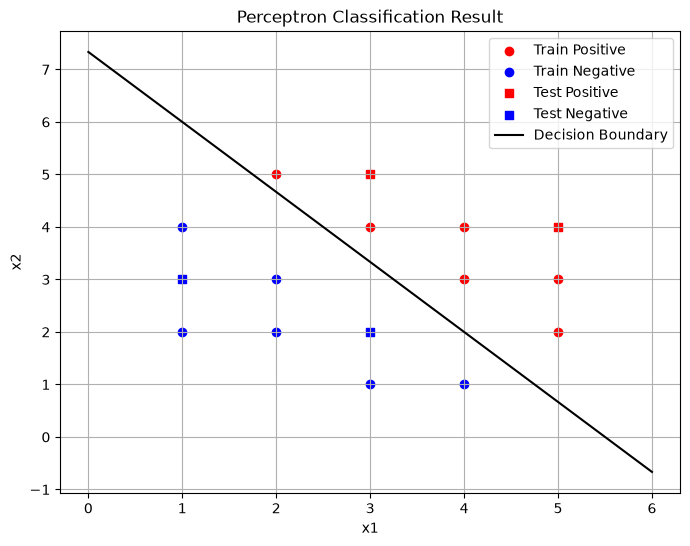

In [5]:
import matplotlib.pyplot as plt

# 假设你已经有：
# X_train, y_train
# X_test, y_test   （如果没有，就用你预测出来的 y_test）
# w, b

plt.figure(figsize=(8, 6))

# ===== 1. 画训练集 =====
train_pos = y_train == 1   # 训练集中的正样本
train_neg = y_train == -1  # 负样本

plt.scatter(
    X_train[train_pos, 0], X_train[train_pos, 1],
    c="red", marker="o", label="Train Positive"
)

plt.scatter(
    X_train[train_neg, 0], X_train[train_neg, 1],
    c="blue", marker="o", label="Train Negative"
)

# ===== 2. 画测试集 =====
test_pos = np.array(y_test) == 1
test_neg = np.array(y_test) == -1

plt.scatter(
    X_test[test_pos, 0], X_test[test_pos, 1],
    c="red", marker="s", label="Test Positive"
)

plt.scatter(
    X_test[test_neg, 0], X_test[test_neg, 1],
    c="blue", marker="s", label="Test Negative"
)

# ===== 3. 画分类超平面 =====
# 超平面：w1*x1 + w2*x2 + b = 0
# 若 w2 != 0，则：
# x2 = -(w1*x1 + b) / w2

x1_min = min(X_train[:, 0].min(), X_test[:, 0].min()) - 1
x1_max = max(X_train[:, 0].max(), X_test[:, 0].max()) + 1

x1_vals = np.linspace(x1_min, x1_max, 200)

if w[1] != 0:
    x2_vals = -(w[0] * x1_vals + b) / w[1]
    plt.plot(x1_vals, x2_vals, c="black", label="Decision Boundary")
else:
    # 特殊情况：w2 = 0，超平面是一条竖线
    x_vertical = -b / w[0]
    plt.axvline(x=x_vertical, c="black", label="Decision Boundary")

# ===== 4. 图形修饰 =====
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Perceptron Classification Result")
plt.legend()
plt.grid(True)
plt.show()

## 总结

1. 为什么要每发现一个误分类点就立即更新？
   感知机原始算法采用逐样本更新策略：每遇到一个误分类点就立即更新参数。这样实现简单，并能及时调整分类超平面，但并不保证每次更新后总误分类数都会减少。
2. 感知机只能对线性可分的二分类问题进行完全划分。如果问题不是线性可分，则需要多层感知机/神经网络。
3. numpy特性：
```python
y == 1 # 对numpy数组y进行逐元素比较，得到一个布尔数组
X[mask] # 用布尔数组筛选行，如：
X[np.array([True, False, True])] # 返回一个numpy矩阵，但是只保留X的0, 2行
X[:, 0] # 返回所有行的第0列元素，是一个向量。如：
X = np.array([
    [1, 2],
    [3, 4],
    [5, 6]
])
X[:, 0] # -> array([1, 3, 5])
(p > 0.5).astype(int) # 返回一个向量，其中值为1(p_i>0.5)或0(else)
```